# 3c_capraz_dogrulama — Gün Öncesi Modelin Yuvarlanan Başlangıçlı Çapraz Doğrulamayla Seçimi

**Neden bu notebook:** `3b_gunoncesi`'de seçim tek bir doğrulama yılına dayanıyordu. Bu yıl resmî plan için olağan dışı zordu (MAPE %3,23; testte %2,60). Doğrulamaya göre seçilen model testte en kötüler arasındaydı; testte en iyi olan hibrit modeller ise doğrulamada geride kalmıştı. Bu notebook seçimi **dört ayrı doğrulama yılının ortalamasına** dayandırıyor.

**Önceden belirlenmiş seçim kuralı (çapraz doğrulama çalıştırılmadan önce yazıldı, değiştirilmeyecek):**
1. **Adaylar:** `3b`'deki beş model. Yeni aday eklenmiyor.
2. **Ölçüt:** Dört katmanın ortalama MAPE'si en düşük model seçilir. RMSPE de raporlanır, ama seçimde kullanılmaz.
3. **Beraberlik:** En iyi modelle arasındaki fark 0,05 puandan küçük olan modeller arasında, **en az özellikli** olan seçilir.
4. **Test:** Test yılı (Eki 2025 – Eyl 2026) seçimde hiç kullanılmaz; yalnızca raporlama için. Beş modelin test sonucu `3b`'de görülmüştü. Bu yüzden bütün modellerin test sonuçları, seçilen modelinkiyle birlikte şeffaf şekilde raporlanacak.

**Revizyon 2 (ilk çalıştırmanın B ve C çıktılarına dayanarak; test sonuçlarına değil):**
1. **Kayma temizliği kapatıldı.** İlk çalıştırmada "bir gün kaymış plan" kuralı 42 günü veri hatası saydı. Ama bu günlerin çoğu gerçek plan hatalarıydı: 4'ü yılbaşı arifesi (31 Aralık), 17'si hafta sonu, ve Nisan 2020'deki sokağa çıkma kısıtlaması hafta sonları. Resmî plan bu günlerde bir önceki normal güne benzer bir tahmin yapıp yanılmış; bu bir veri hatası değil, planın gerçek bir hatası. Kural bu ikisini ayırt edemediği için kayma adayları artık yalnızca raporlanıyor, temizlenmiyor.
2. **Sabit plan kuralı genişletildi:** Standart sapma günlük ortalamanın %1'inden küçükse sabit sayılıyor. İlk kural tam olarak 0 arıyordu. 7 Nisan 2025'te planın gün içi standart sapması 181 MWh'ydi (neredeyse düz bir plan) ve hatası %50'ydi; ilk kural bunu kaçırdı.
3. **Sapma tablosu son 12 aylık pencereyle hesaplanıyor.** GFS'in ERA5'e göre sapması 2021-2024'te yıllık ~+1,0-1,1°C iken 2025'te +0,80°C, 2026'da +0,19°C'ye indi (model güncellemeleri). Tüm geçmişin ortalaması, test yılında sapmayı olduğundan fazla düzeltiyordu.

Seçim kuralı **değişmedi.**

**Bölümler:**
- **A.** Veri ve resmî plan temizliği
- **B.** Resmî planın büyük hatalarının incelenmesi
- **C.** Hava verisi: ERA5, GFS gün öncesi tahmini (Nisan 2021'den) ve sapma düzeltmesi
- **D.** Katman bazlı özellik hazırlığı
- **E.** Çapraz doğrulama (4 katman) ve seçim
- **F.** Seçilen modelin test yılında değerlendirilmesi ve kaydı

## A. Veri ve Resmî Plan Temizliği

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import xgboost as xgb

KOK = r"C:\Deep_Learning_to_AI_Agents\Bitirme_Proje_Bonus"
np.random.seed(42)

df = pd.read_csv(os.path.join(KOK, "data", "tr_ozellikli_saatlik.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
lp = pd.read_csv(os.path.join(KOK, "data", "tr_yuk_plani_saatlik.csv"))
lp["date"] = pd.to_datetime(lp["date"])
df = df.merge(lp[["date", "lep"]], on="date", how="left")
df["gun_t"] = df["date"].dt.tz_localize(None).dt.normalize()

TEST_BAS = pd.Timestamp("2025-10-01T00:00:00+03:00")
TEST_BIT = pd.Timestamp("2026-09-23T00:00:00+03:00")

# 3b ile ayni temel temizlik kurali
oran = df["consumption"] / df["lep"]
sorun = df["lep"].notna() & ((df["lep"] <= 0) | (oran > 2) | (oran < 0.5))
df.loc[sorun, "lep"] = np.nan
print("Satir:", len(df), "| temel kuralla temizlenen plan saati:", int(sorun.sum()),
      "| planin eksik oldugu saat:", int(df["lep"].isna().sum()))

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"RMSPE": float(np.sqrt(np.mean(((y - p) / y) ** 2))),
            "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100),
            "MAE_MWh": float(np.mean(np.abs(y - p)))}

Satir: 91968 | temel kuralla temizlenen plan saati: 72 | planin eksik oldugu saat: 96


## B. Resmî Planın Büyük Hatalarının İncelenmesi

`3b`'de resmî planın doğrulama yılındaki RMSPE'si (0,0503), MAPE'sine (%3,23) göre yüksekti. Bu, bazı saatlerde çok büyük hatalar olduğuna işaret ediyordu. Bu hatalar iki türlü olabilir:
- **Gerçek tahmin hatası:** Resmî plan o gün gerçekten yanılmış. Veride kalmalı.
- **Veri hatası:** Örneğin planın bir gün kaymış olarak kaydedilmesi, ya da gün boyunca sabit bir değer. Temizlenmeli.

**Veri hatası kuralı (Revizyon 2):**
1. **Sabit plan:** Planın gün içi standart sapması, günlük ortalamasının %1'inden küçükse o gün veri hatası sayılır ve plan değerleri boş (NaN) yapılır. Gerçek bir saatlik yük tahmini gün içinde bu kadar düz olamaz.
2. **Kayma adayları yalnızca raporlanıyor:** Hatası %5'in üstünde olan, özel olmayan günlerde, planın komşu günün tüketimine daha çok benzediği durumlar. `KAYMA_TEMIZLIGI = False`. İlk çalıştırmada bu kural, yılbaşı arifesi ve sokağa çıkma kısıtlaması gibi gerçek plan hatalarını veri hatası sanmıştı.
3. **Hatası %15'in üstündeki bütün günler** özel gün bilgisiyle listeleniyor; incelemek için.

In [2]:
d = df.dropna(subset=["lep"]).copy()
d["ape"] = (d["lep"] - d["consumption"]).abs() / d["consumption"] * 100
d["donem"] = np.select([d["date"] < pd.Timestamp("2024-10-01T00:00:00+03:00"), d["date"] < TEST_BAS],
                       ["2016-2024", "dogrulama yili (2024-25)"], default="test yili (2025-26)")
print("Buyuk hata saatlerinin payi (%):")
print(d.groupby("donem")["ape"].agg(saat="size", ort="mean", ust10=lambda s: (s > 10).mean() * 100,
                                     ust20=lambda s: (s > 20).mean() * 100).round(2).to_string())

KAYMA_TEMIZLIGI = False
gun = d.groupby("gun_t").agg(n=("ape", "size"), gun_mape=("ape", "mean"), lep_std=("lep", "std"), lep_ort=("lep", "mean"),
                              tatil=("tatil_tam", "max"), yarim=("tatil_yarim", "max"), izin=("idari_izin", "max"),
                              once=("bayram_once_gun", "min"), sonra=("bayram_sonra_gun", "min"))
gun["ozel"] = (gun["tatil"] == 1) | (gun["yarim"] == 1) | (gun["izin"] == 1) | (gun["once"] <= 1) | (gun["sonra"] <= 1)
gun["sabit"] = (gun["n"] == 24) & (gun["lep_std"] < 0.01 * gun["lep_ort"])
tam_gun = df.set_index("date")

def kaydirma_mape(g, k):
    p = df.loc[df["gun_t"] == g, ["date", "lep"]].set_index("date")["lep"]
    ger = tam_gun["consumption"].reindex(p.index + pd.Timedelta(days=k))
    ok = ger.notna().values & p.notna().values
    return float(np.mean(np.abs(p.values[ok] - ger.values[ok]) / ger.values[ok]) * 100) if ok.sum() >= 20 else np.nan

kontrol = gun[(gun["n"] == 24) & (gun["gun_mape"] > 5) & ~gun["ozel"]].copy()
kontrol["mape_dun"] = [kaydirma_mape(g, -1) for g in kontrol.index]
kontrol["mape_yarin"] = [kaydirma_mape(g, +1) for g in kontrol.index]
kontrol["kayma"] = np.fmin(kontrol["mape_dun"], kontrol["mape_yarin"]) < 0.5 * kontrol["gun_mape"]
gun = gun.join(kontrol[["mape_dun", "mape_yarin", "kayma"]])
gun["kayma"] = gun["kayma"].eq(True)
gun["veri_hatasi"] = gun["sabit"] | (gun["kayma"] & KAYMA_TEMIZLIGI)

print(f"\nKayma kontrolu yapilan gun (MAPE > %5, ozel degil): {len(kontrol)} | sabit plan gunu: {int(gun['sabit'].sum())} | "
      f"kayma adayi (temizlenmiyor): {int(gun['kayma'].sum())}")
ka = gun[gun["kayma"]]
print("Kayma adaylarinin haftanin gunune gore dagilimi:", ka.index.day_name().value_counts().to_dict())
print("Kayma adaylari icindeki 31 Aralik gunleri:", [str(g.date()) for g in ka.index if g.month == 12 and g.day == 31])
buyuk = gun[(gun["n"] == 24) & (gun["gun_mape"] > 15)]
print(f"Plan MAPE'si %15'in ustundeki gun: {len(buyuk)} (ozel gun: {int(buyuk['ozel'].sum())}) - en buyuk 25:")
print(buyuk.sort_values("gun_mape", ascending=False).head(25)[["gun_mape", "mape_dun", "mape_yarin", "lep_std", "lep_ort",
      "ozel", "sabit", "kayma", "veri_hatasi"]].round(2).to_string())
if gun["veri_hatasi"].any():
    print("\nVeri hatasi sayilan gunler:")
    print(gun[gun["veri_hatasi"]][["gun_mape", "lep_std", "lep_ort", "sabit", "kayma"]].round(2).to_string())

hatali_gunler = set(gun.index[gun["veri_hatasi"]])
df.loc[df["gun_t"].isin(hatali_gunler), "lep"] = np.nan
print("\nVeri hatasi nedeniyle bosaltilan gun:", sorted(str(g.date()) for g in hatali_gunler))
print("Planin eksik oldugu toplam saat:", int(df["lep"].isna().sum()))

Buyuk hata saatlerinin payi (%):
                           saat   ort  ust10  ust20
donem                                              
2016-2024                 74448  2.80   3.03   0.32
dogrulama yili (2024-25)   8760  3.23   2.82   0.34
test yili (2025-26)        8664  2.59   1.63   0.12

Kayma kontrolu yapilan gun (MAPE > %5, ozel degil): 307 | sabit plan gunu: 1 | kayma adayi (temizlenmiyor): 42
Kayma adaylarinin haftanin gunune gore dagilimi: {'Saturday': 14, 'Tuesday': 9, 'Friday': 6, 'Wednesday': 4, 'Monday': 3, 'Thursday': 3, 'Sunday': 3}
Kayma adaylari icindeki 31 Aralik gunleri: ['2019-12-31', '2020-12-31', '2021-12-31', '2022-12-31']
Plan MAPE'si %15'in ustundeki gun: 18 (ozel gun: 13) - en buyuk 25:
            gun_mape  mape_dun  mape_yarin  lep_std   lep_ort   ozel  sabit  kayma  veri_hatasi
gun_t                                                                                          
2025-04-07     50.15     74.58       42.75   181.44  56005.67  False   True  False   

## C. Hava Verisi

**Kaynaklar:**
- **ERA5 (gerçekleşen):** `3b`'nin önbelleğe aldığı `data/om_era5_<il>.csv` dosyaları kullanılıyor; yoksa indiriliyor.
- **GFS gün öncesi tahmini:** Previous Runs API, `temperature_2m_previous_day1`, `models=gfs_seamless`. GFS'in 2 metre sıcaklık arşivi Mart 2021'e kadar gidiyor. Bu yüzden indirme Nisan 2021'den başlıyor; ilk doğrulama katmanı (Ekim 2021) için tahmin geçmişi de sapma hesabı için birkaç ay veri de mevcut. Yeni önbellek dosyaları `data/om_tahmin_uzun_<il>.csv`.

**Kullanım sınırı:** Open-Meteo, ticari olmayan kullanımda günde 10.000 isteğe kadar ücretsiz. Bu bölüm yaklaşık 130 istek gönderiyor.

**Sapma düzeltmesi:** `3b`'de GFS tahmininin ERA5'e göre ortalama +0,5-0,7°C sıcak olduğu görülmüştü. Model ERA5 ile eğitilip tahminle çalıştırıldığı için bu sapma modele yanlış bilgi veriyor. Düzeltme şöyle yapılıyor:
- Ağırlıklı sıcaklıkta (tahmin − ERA5) farkının **ay × saat** ortalaması hesaplanıyor. İlgili ay-saat hücresinde veri yoksa yalnızca saat ortalaması, o da yoksa 0 kullanılıyor.
- Bu tablo her katmanda **yalnızca kesimden önceki son 12 ayın** verisiyle hesaplanıyor (Revizyon 2). GFS'in sapması yıllar içinde azaldığı için, uzak geçmişin ortalaması güncel sapmayı temsil etmiyor. İlk katmanda (Ekim 2021) tahmin geçmişi yalnızca 6 ay; eksik ay-saat hücrelerinde saat ortalaması kullanılıyor.
- Hesaplanan sapma, tahminden çıkarılıyor.

In [3]:
SEHIRLER = {  # il: (enlem, boylam, TUIK 2024 nufusu)
    "istanbul": (41.01, 28.98, 15701602), "ankara": (39.93, 32.86, 5864049), "izmir": (38.42, 27.14, 4493242),
    "bursa": (40.19, 29.06, 3238618), "antalya": (36.90, 30.70, 2722103), "adana": (37.00, 35.32, 2280484),
}
toplam_nufus = sum(v[2] for v in SEHIRLER.values())
AGIRLIK = {k: v[2] / toplam_nufus for k, v in SEHIRLER.items()}
ARSIV = "https://archive-api.open-meteo.com/v1/archive"
ONCEKI = "https://previous-runs-api.open-meteo.com/v1/forecast"
TAHMIN_BAS = "2021-04-01"

def om_get(url, params):
    for deneme, bekle in enumerate([0, 10, 30, 60, 120], start=1):
        time.sleep(bekle)
        try:
            r = requests.get(url, params=params, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"  deneme {deneme}: HTTP {r.status_code} {r.text[:150]}")
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            print(f"  deneme {deneme}: {str(e)[:150]}")
    raise RuntimeError(f"Open-Meteo istegi basarisiz: {params.get('start_date')}")

def om_seri(js, degisken):
    zaman = [t + ":00+03:00" for t in js["hourly"]["time"]]
    return pd.Series(js["hourly"][degisken], index=pd.to_datetime(zaman), dtype="float64")

# C1: en erken tahmin doneminin testi (Nisan 2021 arsivi gercekten var mi?)
enl, boy, _ = SEHIRLER["ankara"]
js = om_get(ONCEKI, {"latitude": enl, "longitude": boy, "start_date": TAHMIN_BAS, "end_date": "2021-04-07",
                     "hourly": "temperature_2m_previous_day1", "models": "gfs_seamless", "timezone": "Europe/Istanbul"})
ilk = om_seri(js, "temperature_2m_previous_day1")
print(f"Ankara {TAHMIN_BAS} haftasi: {len(ilk)} saat, bos {int(ilk.isna().sum())}")

Ankara 2021-04-01 haftasi: 168 saat, bos 0


In [4]:
def indir(sehir, tur):
    dosya = {"era5": f"om_era5_{sehir}.csv", "tahmin": f"om_tahmin_uzun_{sehir}.csv"}[tur]
    yol = os.path.join(KOK, "data", dosya)
    if os.path.exists(yol):
        s = pd.read_csv(yol)
        return pd.Series(s["deger"].values, index=pd.to_datetime(s["date"]))
    enl, boy, _ = SEHIRLER[sehir]
    if tur == "era5":
        araliklar = [(f"{y}-01-01" if y > 2016 else "2016-04-01", f"{y}-12-31" if y < 2026 else "2026-09-22")
                     for y in range(2016, 2027)]
        url, deg, ek = ARSIV, "temperature_2m", {}
    else:
        bas = pd.date_range(TAHMIN_BAS, "2026-07-01", freq="QS-OCT")
        araliklar = [(b.strftime("%Y-%m-%d"),
                      min(b + pd.offsets.QuarterEnd(0), pd.Timestamp("2026-09-22")).strftime("%Y-%m-%d")) for b in bas]
        url, deg, ek = ONCEKI, "temperature_2m_previous_day1", {"models": "gfs_seamless"}
    parcalar = []
    for b, s in araliklar:
        parcalar.append(om_seri(om_get(url, {"latitude": enl, "longitude": boy, "start_date": b, "end_date": s,
                                             "hourly": deg, "timezone": "Europe/Istanbul", **ek}), deg))
        time.sleep(1.0)
    seri = pd.concat(parcalar)
    seri = seri[~seri.index.duplicated()].sort_index()
    pd.DataFrame({"date": seri.index, "deger": seri.values}).to_csv(yol, index=False)
    return seri

era5 = {s: indir(s, "era5") for s in SEHIRLER}
tahm = {s: indir(s, "tahmin") for s in SEHIRLER}
for s in SEHIRLER:
    print(f"{s:9s} | ERA5 {len(era5[s]):6d} saat | tahmin {len(tahm[s]):6d} saat "
          f"({tahm[s].index.min().date()} -> {tahm[s].index.max().date()}, bos {int(tahm[s].isna().sum())})")

def agirlikli(sozluk):
    return (pd.DataFrame(sozluk) * pd.Series(AGIRLIK)).sum(axis=1, min_count=len(SEHIRLER))

idx = pd.DatetimeIndex(df["date"])
df["om_era5"] = agirlikli(era5).reindex(idx).values
df["om_fc_ham"] = agirlikli(tahm).reindex(idx).values
df["om_tgun_era5"] = df.groupby("gun_t")["om_era5"].transform("mean")
fark = df["om_fc_ham"] - df["om_era5"]
print("\nGFS tahmini - ERA5 (agirlikli), yillara gore ortalama sapma (C):")
print(fark.groupby(df["date"].dt.year).agg(["count", "mean", lambda s: s.abs().mean()]).round(2)
      .rename(columns={"<lambda_0>": "ort_mutlak"}).dropna().to_string())

istanbul  | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)
ankara    | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)
izmir     | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)
bursa     | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)
antalya   | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)
adana     | ERA5  91848 saat | tahmin  48024 saat (2021-04-01 -> 2026-09-22, bos 492)

GFS tahmini - ERA5 (agirlikli), yillara gore ortalama sapma (C):
      count  mean  ort_mutlak
date                         
2021   6600  1.12        1.21
2022   8760  1.01        1.14
2023   8715  1.01        1.13
2024   8337  1.09        1.18
2025   8760  0.80        0.98
2026   6360  0.19        0.60


## D. Katman Bazlı Özellik Hazırlığı

`hazirla(kesim)` fonksiyonu, doğrulama yılının başlangıcı olan bir kesim tarihinden önceki bilgiyle bütün özellikleri üretir:

| Özellik | Kesimden önce | Kesimden sonra |
|---|---|---|
| Ankara HDD/CDD bazları | Kesimden önceki normal iş günlerinden seçilir | Aynı bazlar kullanılır |
| Ağırlıklı sıcaklık | ERA5 (gerçekleşen) | Sapması düzeltilmiş GFS gün öncesi tahmini |
| Sapma tablosu | Kesimden önceki son 12 ayın tahmin-ERA5 farklarından | — |
| Ağırlıklı sıcaklık HDD/CDD bazları | Kesimden önceki ERA5'ten seçilir | Aynı bazlar kullanılır |

Böylece hiçbir katmanda, doğrulama yılının bilgisi özellik tanımına sızmıyor. `3_model`'de Ankara bazları 2024-09'a kadarki veriyle seçilmişti; bu, erken katmanlar için doğrulama yılını da içeriyordu. Burada her katmanda yeniden seçiliyor.

In [5]:
df["lag_48"] = df["consumption"].shift(48)
df["lag_72"] = df["consumption"].shift(72)
df["rol_24_48"] = df["consumption"].shift(48).rolling(24).mean()
df["rol_168_48"] = df["consumption"].shift(48).rolling(168).mean()
df["tavg_dun"] = df["tavg_c"].shift(24)
df["lep_hata"] = df["lep"] - df["consumption"]
df["lep_hata_48"] = df["lep_hata"].shift(48)
df["lep_hata_168"] = df["lep_hata"].shift(168)
df["lep_hata_ort_7g"] = df["lep_hata"].shift(48).rolling(168, min_periods=120).mean()
df["lep_oran_hedef"] = df["consumption"] / df["lep"] - 1

TAKVIM = ["saat", "gun", "ay", "hafta_sonu", "tatil_saat", "idari_izin", "bayram_gun_no",
          "bayram_once_gun", "bayram_sonra_gun"]
GO_LAG = ["lag_48", "lag_72", "lag_168", "rol_24_48", "rol_168_48"]
HIBRIT = ["lep", "lep_hata_48", "lep_hata_168", "lep_hata_ort_7g"]
ANKARA = ["tavg_dun", "hdd_dun", "cdd_dun"]
OM = ["om_t", "om_tgun", "om_hdd", "om_cdd"]
MODELLER = {  # ad: (ozellikler, hedef)
    "Referans (3_model)": (TAKVIM + ANKARA + GO_LAG, "seviye"),
    "XGBoost + Open-Meteo": (TAKVIM + GO_LAG + OM, "seviye"),
    "Hibrit (seviye)": (TAKVIM + ANKARA + GO_LAG + HIBRIT, "seviye"),
    "Hibrit (oran)": (TAKVIM + ANKARA + GO_LAG + HIBRIT, "oran"),
    "Hibrit (oran) + Open-Meteo": (TAKVIM + GO_LAG + HIBRIT + OM, "oran"),
}
for ad, (f, h) in MODELLER.items():
    print(f"{ad}: {len(f)} ozellik, hedef {h}")

def baz_sec(d, tcol, bh_aralik, bc_aralik):
    g = d.groupby("gun_t").agg(tuketim=("consumption", "sum"), n=("consumption", "size"), t=(tcol, "first"),
                               tam=("tatil_tam", "max"), yarim=("tatil_yarim", "max"), izin=("idari_izin", "max"),
                               once=("bayram_once_gun", "first"), sonra=("bayram_sonra_gun", "first"))
    g = g[(g.index.dayofweek < 5) & (g["n"] == 24) & (g["tam"] == 0) & (g["yarim"] == 0) & (g["izin"] == 0)
          & (g["once"] > 3) & (g["sonra"] > 3) & g["t"].notna()]
    T, y = g["t"].values, g["tuketim"].values
    yd = pd.get_dummies(g.index.year, drop_first=True).values.astype(float)
    en_iyi = (None, None, -np.inf)
    for bh in bh_aralik:
        for bc in bc_aralik:
            if bc < bh:
                continue
            X = np.column_stack([np.ones(len(y)), np.maximum(0, bh - T), np.maximum(0, T - bc), yd])
            b, *_ = np.linalg.lstsq(X, y, rcond=None)
            r2 = 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()
            if r2 > en_iyi[2]:
                en_iyi = (float(bh), float(bc), float(r2))
    return en_iyi

def hazirla(kesim):
    d = df.copy()
    once = d["date"] < kesim
    bh, bc, r2a = baz_sec(d[once], "tavg_c", np.arange(10, 22.5, 0.5), np.arange(14, 26.5, 0.5))
    d["hdd_dun"] = np.maximum(0, bh - d["tavg_dun"])
    d["cdd_dun"] = np.maximum(0, d["tavg_dun"] - bc)

    m = once & (d["date"] >= kesim - pd.DateOffset(months=12)) & d["om_fc_ham"].notna() & d["om_era5"].notna()
    fk = d.loc[m, "om_fc_ham"] - d.loc[m, "om_era5"]
    ay, sa = d["date"].dt.month, d["date"].dt.hour
    tab = fk.groupby([ay[m].values, sa[m].values]).mean()
    saat_tab = fk.groupby(sa[m].values).mean()
    sapma = pd.Series(tab.reindex(pd.MultiIndex.from_arrays([ay.values, sa.values])).values, index=d.index)
    sapma = sapma.fillna(pd.Series(saat_tab.reindex(sa.values).values, index=d.index)).fillna(0.0)
    d["om_t"] = np.where(once, d["om_era5"], d["om_fc_ham"] - sapma)
    d["om_tgun"] = d.groupby("gun_t")["om_t"].transform("mean")
    bh2, bc2, r2o = baz_sec(d[once], "om_tgun_era5", np.arange(8, 22.5, 0.5), np.arange(14, 28.5, 0.5))
    d["om_hdd"] = np.maximum(0, bh2 - d["om_tgun"])
    d["om_cdd"] = np.maximum(0, d["om_tgun"] - bc2)
    bilgi = {"ankara_bazlari": (bh, bc, round(r2a, 4)), "om_bazlari": (bh2, bc2, round(r2o, 4)),
             "sapma_saat_sayisi": int(m.sum()), "ay_saat_hucresi": int(len(tab)),
             "ortalama_sapma_c": round(float(fk.mean()), 3) if len(fk) else None}
    tablo = {f"{a}-{s}": round(float(v), 4) for (a, s), v in tab.items()}
    return d, bilgi, tablo

_, b_ornek, _ = hazirla(TEST_BAS)
print("\nTest kesimi icin ornek:", b_ornek)

Referans (3_model): 17 ozellik, hedef seviye
XGBoost + Open-Meteo: 18 ozellik, hedef seviye
Hibrit (seviye): 21 ozellik, hedef seviye
Hibrit (oran): 21 ozellik, hedef oran
Hibrit (oran) + Open-Meteo: 22 ozellik, hedef oran

Test kesimi icin ornek: {'ankara_bazlari': (14.0, 17.0, 0.845), 'om_bazlari': (15.5, 20.0, 0.881), 'sapma_saat_sayisi': 8760, 'ay_saat_hucresi': 288, 'ortalama_sapma_c': 0.694}


## E. Çapraz Doğrulama

| Katman | Doğrulama yılı | Eğitim | Erken durdurma |
|---|---|---|---|
| 1 | Eki 2021 – Eyl 2022 | 2016-04 → 2021-03 | 2021-04 → 2021-09 |
| 2 | Eki 2022 – Eyl 2023 | 2016-04 → 2022-03 | 2022-04 → 2022-09 |
| 3 | Eki 2023 – Eyl 2024 | 2016-04 → 2023-03 | 2023-04 → 2023-09 |
| 4 | Eki 2024 – Eyl 2025 | 2016-04 → 2024-03 | 2024-04 → 2024-09 |

- **Genişleyen pencere:** Her katmanda eğitim, doğrulama yılından önceki bütün veriyi kullanıyor.
- **Erken durdurma:** Eğitim verisinin son 6 ayı; doğrulama yılı modele hiçbir şekilde girmiyor.
- **Karşılaştırma:** Her katmanda bütün modeller ve resmî plan, aynı saatler üzerinde değerlendiriliyor.

**Süre:** 5 model × 4 katman = 20 eğitim; yaklaşık 5-10 dakika.

In [6]:
XGB_PARAM = dict(n_estimators=3000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8,
                 colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", early_stopping_rounds=100,
                 eval_metric="rmse", random_state=42, n_jobs=-1)
TUM_OZ = list(dict.fromkeys(sum([f for f, _ in MODELLER.values()], [])))

def katman(kesim, bitis, modeller_don=False):
    d, bilgi, tablo = hazirla(kesim)
    es_bas = kesim - pd.DateOffset(months=6)
    temel_gerekli = ["consumption", "lep_oran_hedef"]
    egt = d[d["date"] < es_bas].dropna(subset=TUM_OZ + temel_gerekli)
    es = d[(d["date"] >= es_bas) & (d["date"] < kesim)].dropna(subset=TUM_OZ + temel_gerekli)
    dg = d[(d["date"] >= kesim) & (d["date"] < bitis)].dropna(subset=TUM_OZ + temel_gerekli)
    egt = egt[np.isfinite(egt["lep_oran_hedef"])]
    es = es[np.isfinite(es["lep_oran_hedef"])]
    sonuc, tahmin, egitilmis = {}, {"date": dg["date"].reset_index(drop=True), "gercek": dg["consumption"].values}, {}
    for ad, (f, hedef) in MODELLER.items():
        hc = "consumption" if hedef == "seviye" else "lep_oran_hedef"
        m = xgb.XGBRegressor(**XGB_PARAM)
        m.fit(egt[f], egt[hc], eval_set=[(es[f], es[hc])], verbose=False)
        p = m.predict(dg[f])
        if hedef == "oran":
            p = dg["lep"].values * (1 + p)
        sonuc[ad] = metrik(dg["consumption"], p)
        tahmin[ad] = p
        egitilmis[ad] = m
    sonuc["Resmi Yuk Tahmin Plani"] = metrik(dg["consumption"], dg["lep"])
    tahmin["Resmi Yuk Tahmin Plani"] = dg["lep"].values
    bilgi.update({"egitim_saat": len(egt), "erken_durdurma_saat": len(es), "degerlendirme_saat": len(dg)})
    cikti = (sonuc, pd.DataFrame(tahmin), bilgi, tablo, dg)
    return cikti + ((egitilmis,) if modeller_don else ())

KATMANLAR = [(pd.Timestamp(f"{y}-10-01T00:00:00+03:00"), pd.Timestamp(f"{y + 1}-10-01T00:00:00+03:00"))
             for y in [2021, 2022, 2023, 2024]]
cv = {}
for k, (bas, bit) in enumerate(KATMANLAR, start=1):
    t0 = time.time()
    s, _, bilgi, _, _ = katman(bas, bit)
    cv[k] = s
    print(f"Katman {k} ({bas.date()} -> {(bit - pd.Timedelta(days=1)).date()}): {time.time() - t0:.0f} sn | {bilgi}")
    print("   " + " | ".join(f"{a}: %{v['MAPE_%']:.2f}" for a, v in s.items()))

Katman 1 (2021-10-01 -> 2022-09-30): 12 sn | {'ankara_bazlari': (13.5, 17.0, 0.7341), 'om_bazlari': (15.5, 20.0, 0.7835), 'sapma_saat_sayisi': 4392, 'ay_saat_hucresi': 144, 'ortalama_sapma_c': 1.176, 'egitim_saat': 43464, 'erken_durdurma_saat': 4392, 'degerlendirme_saat': 8760}
   Referans (3_model): %3.14 | XGBoost + Open-Meteo: %3.31 | Hibrit (seviye): %2.79 | Hibrit (oran): %2.70 | Hibrit (oran) + Open-Meteo: %2.66 | Resmi Yuk Tahmin Plani: %2.74
Katman 2 (2022-10-01 -> 2023-09-30): 30 sn | {'ankara_bazlari': (14.0, 17.0, 0.7748), 'om_bazlari': (15.5, 20.0, 0.8185), 'sapma_saat_sayisi': 8760, 'ay_saat_hucresi': 288, 'ortalama_sapma_c': 0.914, 'egitim_saat': 52224, 'erken_durdurma_saat': 4392, 'degerlendirme_saat': 8760}
   Referans (3_model): %2.37 | XGBoost + Open-Meteo: %2.19 | Hibrit (seviye): %2.16 | Hibrit (oran): %2.63 | Hibrit (oran) + Open-Meteo: %2.13 | Resmi Yuk Tahmin Plani: %2.77
Katman 3 (2023-10-01 -> 2024-09-30): 63 sn | {'ankara_bazlari': (13.0, 17.0, 0.7864), 'om_ba

### E2. Seçim (önceden belirlenmiş kural)

Katman bazinda MAPE (%):
                               1     2     3     4
Referans (3_model)          3.14  2.37  2.48  2.74
XGBoost + Open-Meteo        3.31  2.19  2.36  2.88
Hibrit (seviye)             2.79  2.16  2.55  2.62
Hibrit (oran)               2.70  2.63  2.61  2.51
Hibrit (oran) + Open-Meteo  2.66  2.13  2.53  2.56
Resmi Yuk Tahmin Plani      2.74  2.77  3.46  3.10

Ozet:
                            ort_MAPE_%  std_MAPE  ort_RMSPE  plani_gectigi_katman  ozellik_sayisi
Hibrit (oran) + Open-Meteo      2.4722    0.2344     0.0353                     4              22
Hibrit (seviye)                 2.5326    0.2661     0.0344                     3              21
Hibrit (oran)                   2.6142    0.0784     0.0371                     4              21
Referans (3_model)              2.6843    0.3418     0.0358                     3              17
XGBoost + Open-Meteo            2.6849    0.5081     0.0354                     3              18
Resmi Yuk Tahmin Plani 

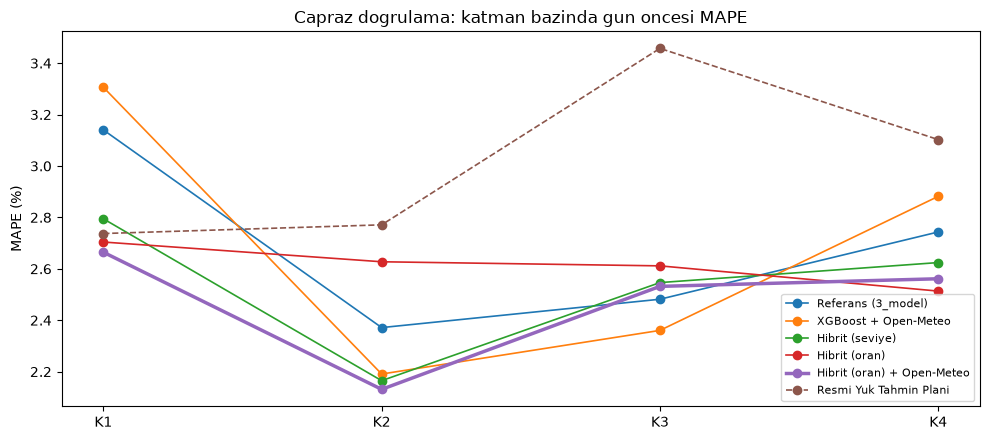

In [7]:
mape = pd.DataFrame({k: {a: v["MAPE_%"] for a, v in s.items()} for k, s in cv.items()})
rmspe = pd.DataFrame({k: {a: v["RMSPE"] for a, v in s.items()} for k, s in cv.items()})
ozet = pd.DataFrame({"ort_MAPE_%": mape.mean(axis=1), "std_MAPE": mape.std(axis=1),
                     "ort_RMSPE": rmspe.mean(axis=1),
                     "plani_gectigi_katman": (mape.lt(mape.loc["Resmi Yuk Tahmin Plani"], axis=1)).sum(axis=1)})
ozet["ozellik_sayisi"] = [len(MODELLER[a][0]) if a in MODELLER else 0 for a in ozet.index]
print("Katman bazinda MAPE (%):")
print(mape.round(2).to_string())
print("\nOzet:")
print(ozet.sort_values("ort_MAPE_%").round(4).to_string())

adaylar = ozet.drop(index="Resmi Yuk Tahmin Plani")
en_iyi_mape = adaylar["ort_MAPE_%"].min()
esit = adaylar[adaylar["ort_MAPE_%"] - en_iyi_mape < 0.05]
SECILEN = esit.sort_values(["ozellik_sayisi", "ort_MAPE_%"]).index[0]
print(f"\nEn dusuk ortalama MAPE: %{en_iyi_mape:.3f}")
print("0,05 puan icindeki modeller:", list(esit.index))
print("SECILEN MODEL:", SECILEN)

fig, ax = plt.subplots(figsize=(10, 4.5))
for a in mape.index:
    stil = "--" if a == "Resmi Yuk Tahmin Plani" else "-"
    ax.plot([f"K{k}" for k in mape.columns], mape.loc[a], stil, marker="o", linewidth=2.5 if a == SECILEN else 1.2, label=a)
ax.set_ylabel("MAPE (%)"); ax.set_title("Capraz dogrulama: katman bazinda gun oncesi MAPE"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(KOK, "graphs", "tr_cv_katman_mape.png"), dpi=150); plt.show()

## F. Test Yılı: Seçilen Modelin Değerlendirmesi

Bütün modeller, test yılından önceki bütün veriyle aynı şekilde yeniden eğitiliyor. Eğitim 2016-04 → 2025-03, erken durdurma 2025-04 → 2025-09. Seçilen model **önceden** belirlendi. Diğer modellerin test sonuçları şeffaflık için raporlanıyor, seçimi değiştirmiyor.

In [8]:
s_test, t_test, b_test, sapma_tablosu, dg_test, egitilmis = katman(TEST_BAS, TEST_BIT, modeller_don=True)
print("Test kesimi bilgisi:", b_test)
tablo = pd.DataFrame(s_test).T.sort_values("MAPE_%")
tablo["secilen"] = ["<<< SECILEN" if a == SECILEN else "" for a in tablo.index]
print(tablo.round(4).to_string())
fark = s_test["Resmi Yuk Tahmin Plani"]["MAPE_%"] - s_test[SECILEN]["MAPE_%"]
print(f"\nSecilen model testte resmi plana gore: {fark:+.2f} MAPE puani ({'model daha iyi' if fark > 0 else 'resmi plan daha iyi'})")

Test kesimi bilgisi: {'ankara_bazlari': (14.0, 17.0, 0.845), 'om_bazlari': (15.5, 20.0, 0.881), 'sapma_saat_sayisi': 8760, 'ay_saat_hucresi': 288, 'ortalama_sapma_c': 0.694, 'egitim_saat': 78528, 'erken_durdurma_saat': 4320, 'degerlendirme_saat': 8496}
                             RMSPE  MAPE_%    MAE_MWh      secilen
Hibrit (oran) + Open-Meteo  0.0302  2.2889   933.6632  <<< SECILEN
Hibrit (seviye)             0.0309  2.2986   954.4169             
Hibrit (oran)               0.0308  2.3032   940.9011             
Resmi Yuk Tahmin Plani      0.0359  2.5990  1044.3640             
Referans (3_model)          0.0353  2.6297  1094.9878             
XGBoost + Open-Meteo        0.0337  2.6600  1107.1561             

Secilen model testte resmi plana gore: +0.31 MAPE puani (model daha iyi)


### F2. Gün tipine ve saate göre hata (test)

In [9]:
t_test["gun_tipi"] = np.select(
    [(dg_test["bayram_once_gun"].values == 0) & (dg_test["bayram_sonra_gun"].values == 0),
     dg_test["tatil_tam"].values == 1, dg_test["idari_izin"].values == 1, dg_test["hafta_sonu"].values == 1],
    ["bayram (arife dahil)", "sabit tatil", "idari izin", "hafta sonu"], default="normal is gunu")
t_test["saat"] = t_test["date"].dt.hour
tum = list(s_test.keys())
ape = pd.DataFrame({a: (t_test["gercek"] - t_test[a]).abs() / t_test["gercek"] * 100 for a in tum})
tip = ape.groupby(t_test["gun_tipi"]).mean()
tip.insert(0, "saat_sayisi", t_test["gun_tipi"].value_counts())
print("Gun tipine gore MAPE (%):"); print(tip.round(2).to_string())
saat = ape.groupby(t_test["saat"]).mean()[[SECILEN, "Resmi Yuk Tahmin Plani"]]
print("\nSaate gore MAPE (%), secilen model ve resmi plan:"); print(saat.round(2).T.to_string())

Gun tipine gore MAPE (%):
                      saat_sayisi  Referans (3_model)  XGBoost + Open-Meteo  Hibrit (seviye)  Hibrit (oran)  Hibrit (oran) + Open-Meteo  Resmi Yuk Tahmin Plani
gun_tipi                                                                                                                                                       
bayram (arife dahil)          216                4.23                  3.79             4.25           4.25                        4.57                    5.31
hafta sonu                   2352                2.68                  2.66             2.20           2.33                        2.21                    2.69
idari izin                     24                5.05                  4.61             8.24           7.55                        8.29                   13.91
normal is gunu               5760                2.51                  2.57             2.23           2.18                        2.20                    2.38
sabit tatil   

### F3. Kayıt

- **Seçilen model:** `agent/tr_xgb_gunoncesi_secilen.json`.
- **Meta dosyası** (`..._meta.json`): Agent'ın tahmini yeniden üretebilmesi için özellikler, hedef türü, bazlar, sapma tablosu, şehir ağırlıkları ve seçim kuralı.
- **Sonuçlar:** `metrics/tr_capraz_dogrulama.json` ve `metrics/tr_gunoncesi_test_tahminleri_3c.csv`.

`3b`'nin kaydettiği `tr_xgb_gunoncesi_en_iyi.json` artık kullanılmamalı.

In [10]:
egitilmis[SECILEN].save_model(os.path.join(KOK, "agent", "tr_xgb_gunoncesi_secilen.json"))
f, hedef = MODELLER[SECILEN]
meta = {"model": SECILEN, "hedef": hedef, "ozellikler": f,
        "secim_kurali": "4 katmanin ortalama MAPE'si; 0,05 puan icindekilerden en az ozellikli",
        "ankara_bazlari_c": b_test["ankara_bazlari"][:2], "om_bazlari_c": b_test["om_bazlari"][:2],
        "sehir_agirliklari": AGIRLIK, "hava_tahmini": "Open-Meteo Previous Runs, gfs_seamless, temperature_2m_previous_day1",
        "sapma_tablosu_ay_saat_c": sapma_tablosu, "plan_veri_hatasi_gunleri": sorted(str(g.date()) for g in hatali_gunler)}
with open(os.path.join(KOK, "agent", "tr_xgb_gunoncesi_secilen_meta.json"), "w", encoding="utf-8") as fh:
    json.dump(meta, fh, ensure_ascii=False, indent=2)
with open(os.path.join(KOK, "metrics", "tr_capraz_dogrulama.json"), "w", encoding="utf-8") as fh:
    json.dump({"secilen": SECILEN, "katman_mape": mape.round(4).to_dict(), "katman_rmspe": rmspe.round(5).to_dict(),
               "ozet": ozet.round(4).to_dict(), "test": s_test, "test_bilgisi": b_test}, fh, ensure_ascii=False, indent=2,
              default=str)
t_test.to_csv(os.path.join(KOK, "metrics", "tr_gunoncesi_test_tahminleri_3c.csv"), index=False)
print("Kaydedildi | secilen:", SECILEN, "| ozellik sayisi:", len(f))

Kaydedildi | secilen: Hibrit (oran) + Open-Meteo | ozellik sayisi: 22


## Yedek modelleri kaydetme

In [11]:
yedekler = {"Hibrit (oran)": ("tr_xgb_gunoncesi_yedek_havasiz", "Hava tahmini yoksa"),
            "Referans (3_model)": ("tr_xgb_gunoncesi_yedek_plansiz", "Resmi plan yoksa")}
for ad, (dosya, kullanim) in yedekler.items():
    egitilmis[ad].save_model(os.path.join(KOK, "agent", dosya + ".json"))
    with open(os.path.join(KOK, "agent", dosya + "_meta.json"), "w", encoding="utf-8") as fh:
        json.dump({"model": ad, "hedef": MODELLER[ad][1], "ozellikler": MODELLER[ad][0], "kullanim": kullanim,
                   "ankara_bazlari_c": b_test["ankara_bazlari"][:2]}, fh, ensure_ascii=False, indent=2)
print("Yedekler kaydedildi:", [v[0] for v in yedekler.values()])

Yedekler kaydedildi: ['tr_xgb_gunoncesi_yedek_havasiz', 'tr_xgb_gunoncesi_yedek_plansiz']


# Faz 3 hazirligi: yedek modeller ve gun oncesi belirsizlik bandi (capraz dogrulama katmanlarindan)

In [12]:
# Faz 3 hazirligi: yedek modeller ve gun oncesi belirsizlik bandi (capraz dogrulama katmanlarindan)
yedekler = {"Hibrit (oran)": ("tr_xgb_gunoncesi_yedek_havasiz", "Hava tahmini yoksa"),
            "Referans (3_model)": ("tr_xgb_gunoncesi_yedek_plansiz", "Resmi plan yoksa veya supheliyse")}
for ad, (dosya, kullanim) in yedekler.items():
    egitilmis[ad].save_model(os.path.join(KOK, "agent", dosya + ".json"))
    with open(os.path.join(KOK, "agent", dosya + "_meta.json"), "w", encoding="utf-8") as fh:
        json.dump({"model": ad, "hedef": MODELLER[ad][1], "ozellikler": MODELLER[ad][0], "kullanim": kullanim,
                   "ankara_bazlari_c": b_test["ankara_bazlari"][:2]}, fh, ensure_ascii=False, indent=2)
print("Yedekler kaydedildi:", [v[0] for v in yedekler.values()])

parcalar = []
for k, (bas, bit) in enumerate(KATMANLAR, start=1):
    _, t, _, _, _ = katman(bas, bit)
    t["katman"] = k
    parcalar.append(t)
kt = pd.concat(parcalar, ignore_index=True)
kt.to_csv(os.path.join(KOK, "metrics", "tr_cv_katman_tahminleri.csv"), index=False)

u = (kt["gercek"] - kt[SECILEN]) / kt[SECILEN]          # eksik tahmin orani
q90 = u.groupby(kt["date"].dt.hour).quantile(0.90)
ust = t_test[SECILEN] * (1 + q90.reindex(t_test["date"].dt.hour.values).values)
kapsama = float((t_test["gercek"] <= ust).mean() * 100)
with open(os.path.join(KOK, "metrics", "tr_gunoncesi_q90.json"), "w", encoding="utf-8") as fh:
    json.dump({"model": SECILEN, "kaynak": "4 capraz dogrulama katmani", "q90_saatlik": {int(h): round(float(v), 5) for h, v in q90.items()},
               "q90_kapsama_test_%": round(kapsama, 2)}, fh, ensure_ascii=False, indent=2)
print("Katman tahminleri:", len(kt), "saat | saatlik q90 (%):", (q90 * 100).round(2).tolist())
print(f"Test yilinda gercek tuketimin temkinli tahminin altinda kalma orani: %{kapsama:.1f} (hedef ~%90)")

Yedekler kaydedildi: ['tr_xgb_gunoncesi_yedek_havasiz', 'tr_xgb_gunoncesi_yedek_plansiz']
Katman tahminleri: 34500 saat | saatlik q90 (%): [3.97, 3.81, 3.76, 3.7, 3.7, 3.73, 4.06, 4.3, 4.4, 4.25, 4.74, 4.77, 4.92, 5.02, 5.18, 5.04, 5.01, 4.94, 4.55, 4.19, 4.18, 4.06, 3.88, 3.9]
Test yilinda gercek tuketimin temkinli tahminin altinda kalma orani: %90.7 (hedef ~%90)
